In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MaxAbsScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

In [66]:
# Load dataset
df = pd.read_csv('/content/emails.csv')

# Display first five rows
print("First 5 rows:")
print(df.head())

# Dataset shape
print("\nDataset Shape:", df.shape)

# Dataset information
print("\nDataset Information:")
print(df.info())

# Check missing values
print("\nMissing Values:", df.isnull().sum().sum())

# Check target distribution
print("\nSpam Distribution:")
print(df['Prediction'].value_counts())

First 5 rows:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

Dataset Shape: (5172, 3002)

Dataset Informatio

In [67]:
# Remove email identifier
df = df.drop('Email No.', axis=1)

# Separate input and output
X = df.drop('Prediction', axis=1)
y = df['Prediction']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Classes:")
print(y.value_counts())

Input Features Shape: (5172, 3000)
Target Shape: (5172,)

Target Classes:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [68]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4137, 3000)
Testing Data: (1035, 3000)


In [69]:
scaler = MaxAbsScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Normalization Completed!")

Normalization Completed!


In [70]:
# Create KNN model
knn = KNeighborsClassifier(n_neighbors=5)

# Train model
knn.fit(X_train, y_train)

# Predict test data
y_pred_knn = knn.predict(X_test)

print("KNN Classification Completed!")

KNN Classification Completed!


In [71]:
# Create SVM model
svm = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42
)

# Train model
svm.fit(X_train, y_train)

# Predict test data
y_pred_svm = svm.predict(X_test)

print("SVM Classification Completed!")

SVM Classification Completed!


In [72]:
# Calculate metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn)
knn_recall = recall_score(y_test, y_pred_knn)
knn_f1 = f1_score(y_test, y_pred_knn)

print("KNN PERFORMANCE")

print("Accuracy:", round(knn_accuracy * 100, 2), "%")
print("Precision:", round(knn_precision * 100, 2), "%")
print("Recall:", round(knn_recall * 100, 2), "%")
print("F1 Score:", round(knn_f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN PERFORMANCE
Accuracy: 86.76 %
Precision: 70.22 %
Recall: 94.33 %
F1 Score: 80.51 %

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.84      0.90       735
           1       0.70      0.94      0.81       300

    accuracy                           0.87      1035
   macro avg       0.84      0.89      0.85      1035
weighted avg       0.89      0.87      0.87      1035



In [73]:
# Calculate metrics
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)

print("SVM PERFORMANCE")

print("Accuracy:", round(svm_accuracy * 100, 2), "%")
print("Precision:", round(svm_precision * 100, 2), "%")
print("Recall:", round(svm_recall * 100, 2), "%")
print("F1 Score:", round(svm_f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM PERFORMANCE
Accuracy: 97.2 %
Precision: 93.29 %
Recall: 97.33 %
F1 Score: 95.27 %

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       735
           1       0.93      0.97      0.95       300

    accuracy                           0.97      1035
   macro avg       0.96      0.97      0.97      1035
weighted avg       0.97      0.97      0.97      1035



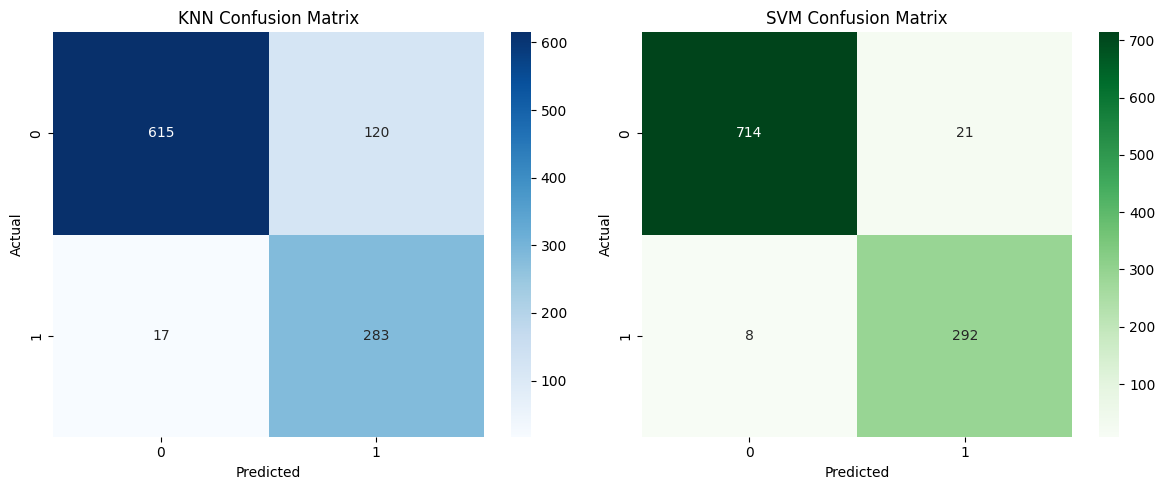

In [74]:
# Calculate confusion matrices
cm_knn = confusion_matrix(y_test, y_pred_knn)
cm_svm = confusion_matrix(y_test, y_pred_svm)

# Plot both confusion matrices
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues'
)
plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.subplot(1, 2, 2)
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Greens'
)
plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

In [75]:
# Create comparison table
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],

    'KNN': [
        knn_accuracy,
        knn_precision,
        knn_recall,
        knn_f1
    ],

    'SVM': [
        svm_accuracy,
        svm_precision,
        svm_recall,
        svm_f1
    ]
})

print("KNN vs SVM Performance Comparison:")
print(comparison.to_string(index=False))

KNN vs SVM Performance Comparison:
   Metric      KNN      SVM
 Accuracy 0.867633 0.971981
Precision 0.702233 0.932907
   Recall 0.943333 0.973333
 F1 Score 0.805121 0.952692


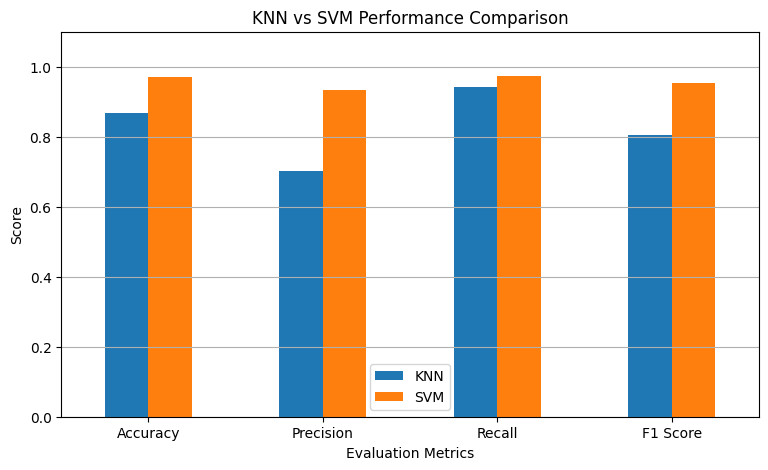

In [76]:
comparison.set_index('Metric').plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('KNN vs SVM Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Evaluation Metrics')
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y')

plt.show()

In [77]:
if svm_accuracy > knn_accuracy:
    print("SVM performs better than KNN.")
elif knn_accuracy > svm_accuracy:
    print("KNN performs better than SVM.")
else:
    print("Both classifiers have equal accuracy.")

print("\nKNN Accuracy:", round(knn_accuracy * 100, 2), "%")
print("SVM Accuracy:", round(svm_accuracy * 100, 2), "%")

SVM performs better than KNN.

KNN Accuracy: 86.76 %
SVM Accuracy: 97.2 %
